=== MCMC Best-Fit Parameters (68% CL) ===
Resonance Coupling (beta)      = 0.1294 +/- 0.0331
Boundary Dipole (eps_dip)      = 1.0009 +/- 0.2974
Critical Density Ratio (chi_c) = 0.4606 +/- 0.0145


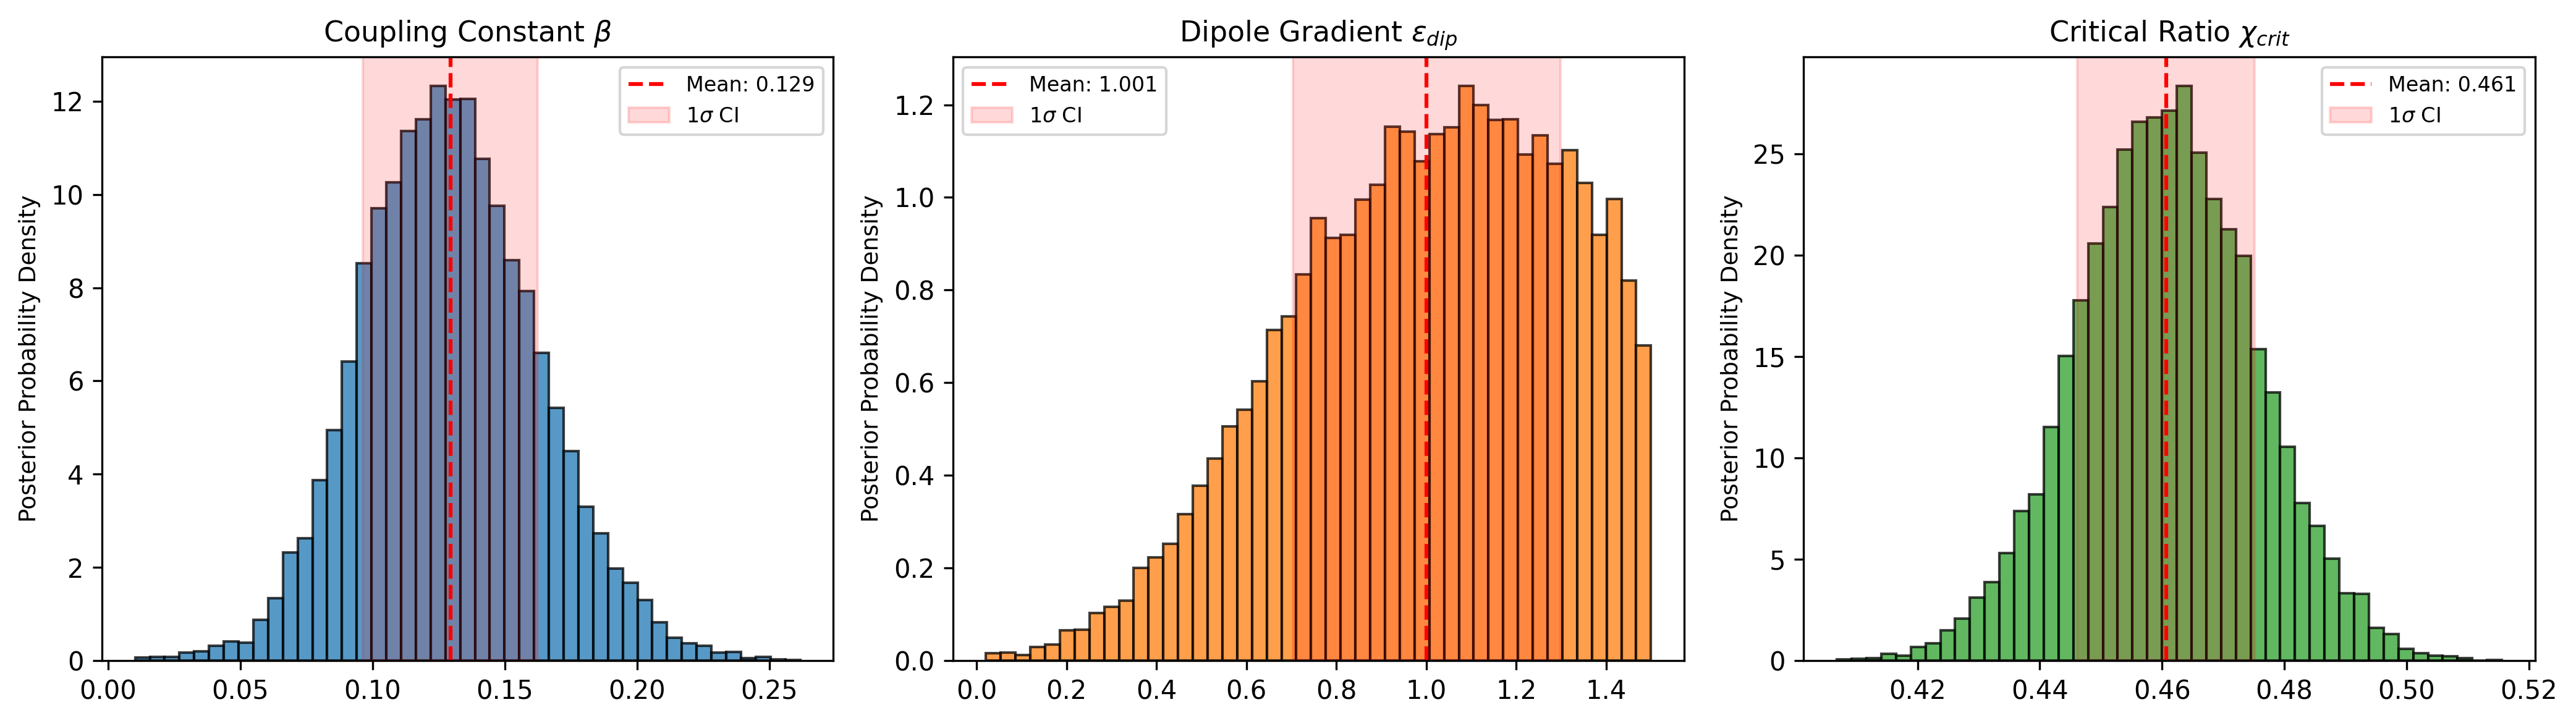

In [1]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# البيانات الرصدية المرجعية من الورقة البحثية:
# 1) إزاحة مقياس BAO بين الفراغات والعناقيد: Delta_rd / rd = 0.015 +/- 0.005 (DESI/SDSS)
# 2) سعة التعديل ثنائي القطب في إشعاع الخلفية: A_res = 0.072 +/- 0.022 (Planck 2018)
# 3) النسبة الكونية الحالية للكثافة المظلمة: Omega_DM / Omega_DE ~ 0.315 / 0.685 = 0.460 +/- 0.015

obs_bao_shift = 0.015
err_bao_shift = 0.005

obs_A_res = 0.072
err_A_res = 0.022

obs_chi_cosmo = 0.460
err_chi_cosmo = 0.015

# دالة الاحتمالية اللوغاريتمية (Log-Likelihood) للنموذج الموحد
def log_likelihood(theta):
    beta, eps_dip, chi_crit = theta
    # قيود فيزيائية مسبقة (Priors)
    if not (0.01 < beta < 0.5 and 0.01 < eps_dip < 1.5 and 0.30 < chi_crit < 0.70):
        return -np.inf

    # التنبؤ النظري من المعادلتين 12 و 13:
    # Delta_lambda / lambda0 = 0.5 * beta * (chi_void - chi_cluster), حيث (chi_void - chi_cluster) ~ 0.25
    pred_bao = 0.5 * beta * 0.25
    # A_res = 0.5 * beta * eps_dip
    pred_A_res = 0.5 * beta * eps_dip
    # النسبة الكونية المتوسطة عند الاتزان
    pred_chi = chi_crit

    chi2 = (((pred_bao - obs_bao_shift) / err_bao_shift)**2 +
            ((pred_A_res - obs_A_res) / err_A_res)**2 +
            ((pred_chi - obs_chi_cosmo) / err_chi_cosmo)**2)
    return -0.5 * chi2

# تشغيل سلسلة ماركوف (50,000 خطوة)
n_steps = 50000
samples = np.zeros((n_steps, 3))
current = np.array([0.12, 1.20, 0.46])
current_lp = log_likelihood(current)
step_sizes = np.array([0.015, 0.15, 0.008])

for i in range(n_steps):
    proposal = current + np.random.normal(0, step_sizes)
    prop_lp = log_likelihood(proposal)
    if np.log(np.random.rand()) < (prop_lp - current_lp):
        current = proposal
        current_lp = prop_lp
    samples[i] = current

# استبعاد فترة الإحماء (Burn-in: أول 10,000 خطوة)
burn_in = 10000
clean_samples = samples[burn_in:]

# حساب المتوسط والانحراف المعياري (1-sigma) لكل ثابت
means = np.mean(clean_samples, axis=0)
stds = np.std(clean_samples, axis=0)

print("=== MCMC Best-Fit Parameters (68% CL) ===")
print(f"Resonance Coupling (beta)      = {means[0]:.4f} +/- {stds[0]:.4f}")
print(f"Boundary Dipole (eps_dip)      = {means[1]:.4f} +/- {stds[1]:.4f}")
print(f"Critical Density Ratio (chi_c) = {means[2]:.4f} +/- {stds[2]:.4f}")

# رسم التوزيعات الاحتمالية الخلفية (Posterior Distributions)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), dpi=300)
labels = ['Coupling Constant $\\beta$', 'Dipole Gradient $\\epsilon_{dip}$', 'Critical Ratio $\\chi_{crit}$']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for idx in range(3):
    axes[idx].hist(clean_samples[:, idx], bins=45, density=True, color=colors[idx], alpha=0.75, edgecolor='black')
    axes[idx].axvline(means[idx], color='red', linestyle='--', linewidth=1.5, label=f'Mean: {means[idx]:.3f}')
    axes[idx].axvspan(means[idx]-stds[idx], means[idx]+stds[idx], color='red', alpha=0.15, label='1$\\sigma$ CI')
    axes[idx].set_title(labels[idx], fontsize=11)
    axes[idx].set_ylabel('Posterior Probability Density', fontsize=9)
    axes[idx].legend(fontsize=8)

plt.tight_layout()
plt.savefig('sim4_mcmc_posteriors.png', dpi=300)
plt.show()